Shape of the image: (1033, 1287, 3)
Pixel at a point: [203 217 233]


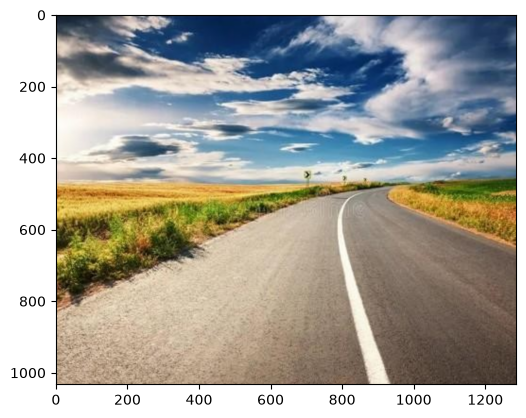

In [210]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('IMG.png')
h = img.shape[0]
w = img.shape[1]

print(f"Shape of the image: {img.shape}")
print(f"Pixel at a point: {img[200, 100]}") #BGR Value

plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.show()

In [211]:
print(f"height : {h}")
print(f"width : {w}")

height : 1033
width : 1287


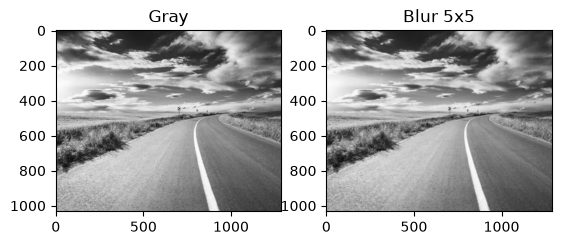

In [212]:
grayImg = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurImg = cv2.GaussianBlur(grayImg, (5, 5), 0)
# plt.imshow(blurImg, cmap='gray')

plt.subplot(1, 2, 1); plt.imshow(grayImg, cmap="gray"); plt.title("Gray")
plt.subplot(1, 2, 2); plt.imshow(cv2.cvtColor(blurImg, cv2.COLOR_BGR2RGB)); plt.title("Blur 5x5")
plt.show()

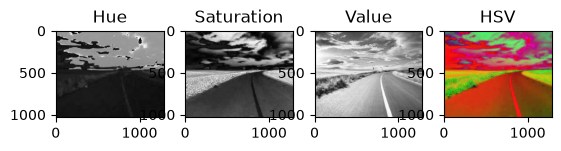

In [213]:
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

hue, saturation, value = cv2.split(hsv)

plt.subplot(1, 4, 1); plt.imshow(hue, cmap="gray"); plt.title("Hue")
plt.subplot(1, 4, 2); plt.imshow(saturation, cmap="gray"); plt.title("Saturation")
plt.subplot(1, 4, 3); plt.imshow(value, cmap="gray"); plt.title("Value")
plt.subplot(1, 4, 4); plt.imshow(cv2.cvtColor(hsv, cv2.COLOR_BGR2RGB)); plt.title("HSV")
plt.show()

In [214]:
#value of hsv at a specific pixel
# print("road1 :", hsv[860, 260])
# print("road2:", hsv[900, 500])
# print("line :", hsv[860, 850])
# print("grass1:", hsv[700, 160])
# print("grass2:", hsv[700, 10])



#road1
# print("road1 :", hsv[540, 160])
# print("road2 :", hsv[580, 330])
# print("line  :", hsv[540, 533])
# print("grass1:", hsv[450, 60])
# print("grass2:", hsv[400, 20])

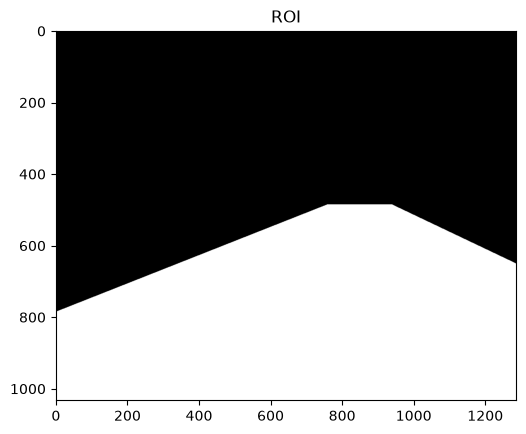

In [215]:
hzn = 0.47

def roi (h, w, horizon = hzn) :
    y = int(h * horizon)
    roi = np.zeros((h, w), dtype=np.uint8)
    poly = np.array([[(0, h), (0, int(h * 0.76)), (int(w * 0.59), y), (int(w * 0.73), y), (w, int(h * 0.63)), (w, h)]], dtype = np.int32)
    cv2.fillPoly(roi, poly, 255)
    return roi

roi_img = roi(h, w)
plt.imshow(roi_img, cmap="gray"); 
plt.title("ROI"); 
plt.show()

232


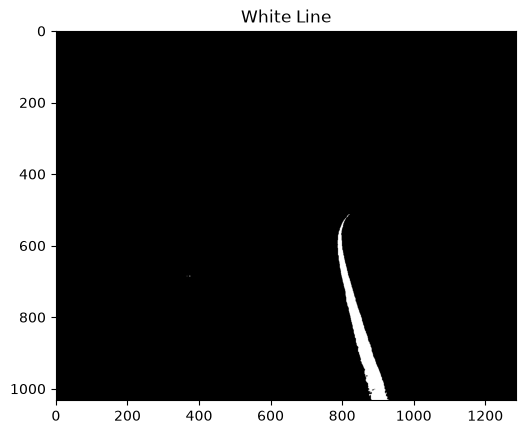

In [216]:
valueCut = max(120, int(np.percentile(value[roi_img>0], 97)))
valueCut = 232
print(valueCut)

whiteLine = cv2.inRange(hsv, (0, 0, valueCut), (180, 40, 255)) 
# whiteLine = cv2.inRange(hsv, (0, 0, valueCut), (190, 45, 255)) 
whiteLine = cv2.bitwise_and(whiteLine, roi_img)
plt.imshow(whiteLine, cmap="gray");
plt.title("White Line");
plt.show()


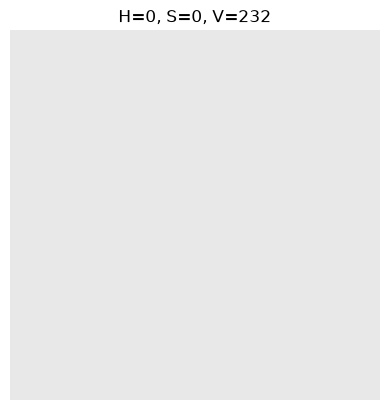

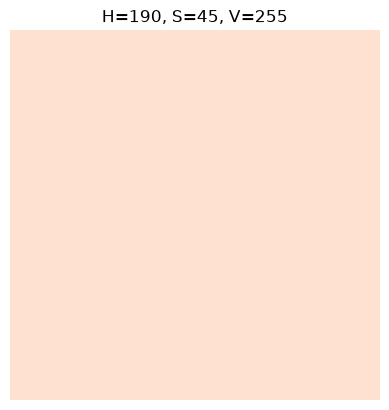

In [217]:
#Just to check color on hsv values

def show_hsv(h, s, v):
    patch = np.full((100, 100, 3), (h, s, v), dtype=np.uint8)  
    rgb = cv2.cvtColor(patch, cv2.COLOR_HSV2RGB)                
    plt.imshow(rgb)
    plt.title(f"H={h}, S={s}, V={v}")
    plt.axis("off")
    plt.show()

show_hsv(0, 0, valueCut)   
show_hsv(190, 45, 255) 


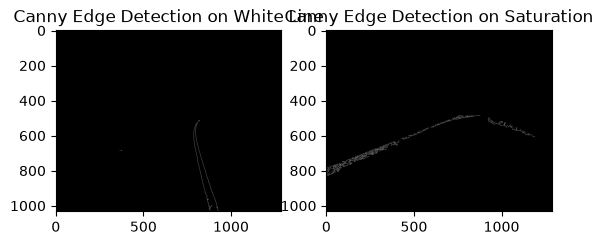

In [218]:
edges_whiteLine = cv2.Canny(whiteLine, 50, 150)
# plt.imshow(edges, cmap="gray");
# plt.title("Canny Edge Detection");
# plt.show()
blur_sat = cv2.GaussianBlur(saturation, (5, 5), 0)
edges_sat = cv2.bitwise_and(cv2.Canny(blur_sat, 50, 150), roi_img)

plt.subplot(1, 2, 1); plt.imshow(edges_whiteLine, cmap="gray"); plt.title("Canny Edge Detection on White Line")
plt.subplot(1, 2, 2); plt.imshow(edges_sat, cmap="gray"); plt.title("Canny Edge Detection on Saturation")
plt.show()

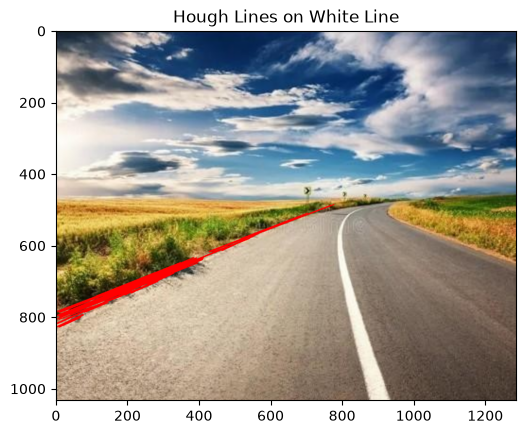

In [219]:
hough_kwords1 = dict(rho=1, theta=np.pi/180, threshold=15, minLineLength=40, maxLineGap=30)
lines_whiteLine1 = cv2.HoughLinesP(edges_whiteLine, **hough_kwords1)
lines_sat1 = cv2.HoughLinesP(edges_sat, **hough_kwords1)

vis1 = img.copy()
for lines in (lines_whiteLine1, lines_sat1):
    if lines is not None:
        for x1, y1, x2, y2 in lines.reshape(-1, 4):
            if (x1 + x2) / 2 > w * 0.5:     
                continue 
            cv2.line(vis1, (x1, y1), (x2, y2), (0, 0, 255), 2) 

# hough_kwords2 = dict(rho=1, theta=np.pi/180, threshold=10, minLineLength=40, maxLineGap=30)
# lines_whiteLine2 = cv2.HoughLinesP(edges_whiteLine, **hough_kwords2)
# lines_sat2 = cv2.HoughLinesP(edges_sat, **hough_kwords2)

# vis2 = img.copy()
# for lines in (lines_whiteLine2, lines_sat2):
#     if lines is not None:
#         for x1, y1, x2, y2 in lines.reshape(-1, 4):
#             cv2.line(vis2, (x1, y1), (x2, y2), (0, 0, 0), 2) 

# hough_kwords3 = dict(rho=1, theta=np.pi/180, threshold=20, minLineLength=40, maxLineGap=30)
# lines_whiteLine3 = cv2.HoughLinesP(edges_whiteLine, **hough_kwords3)
# lines_sat3 = cv2.HoughLinesP(edges_sat, **hough_kwords3)

# vis3 = img.copy()
# for lines in (lines_whiteLine3, lines_sat3):
#     if lines is not None:
#         for x1, y1, x2, y2 in lines.reshape(-1, 4):
#             cv2.line(vis3, (x1, y1), (x2, y2), (0, 0, 0), 2) 

plt.imshow(cv2.cvtColor(vis1, cv2.COLOR_BGR2RGB))
plt.title("Hough Lines on White Line")  
plt.show()
# plt.figure(figsize=(16, 8))
# plt.subplot(1, 3, 1); plt.imshow(cv2.cvtColor(vis1, cv2.COLOR_BGR2RGB)); plt.title("Hough Lines on White Line")
# plt.subplot(1, 3, 2); plt.imshow(cv2.cvtColor(vis2, cv2.COLOR_BGR2RGB)); plt.title("Hough Lines on Saturation")
# plt.subplot(1, 3, 3); plt.imshow(cv2.cvtColor(vis3, cv2.COLOR_BGR2RGB)); plt.title("Hough Lines on Both")
# plt.show()

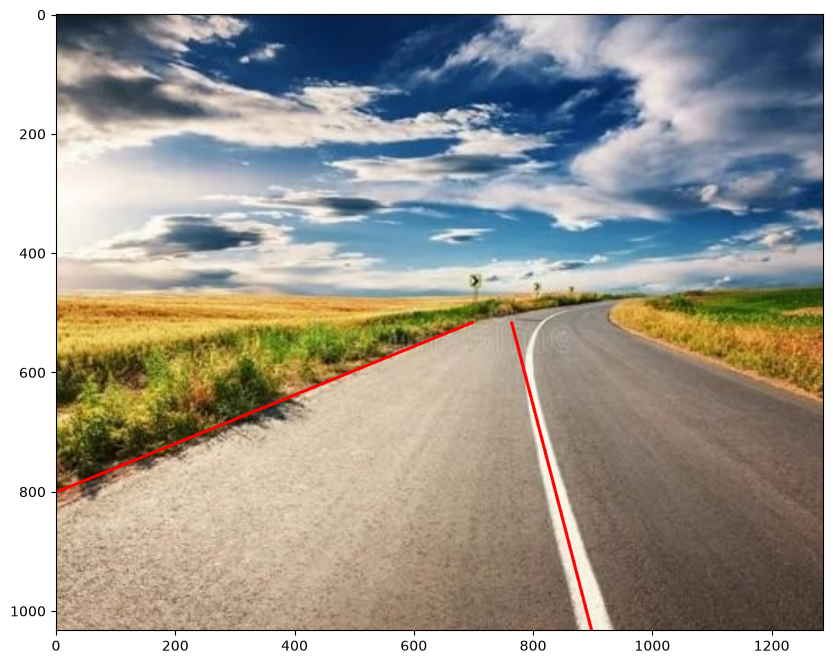

In [220]:
def avgLine (lines, side, x_min=None, x_max=None):
    slopes, constants, lengths = [], [], []
    if lines is None:
        return None
    
    for x1, y1, x2, y2 in lines.reshape(-1, 4):
        if y1==y2:
            continue
        slope = (y2 - y1) / (x2 - x1) if x2 != x1 else float('inf')
        if side == 'left' and slope > -0.2:
            continue
        if side == 'right' and slope < 0.2:
            continue
        midpoint_x = (x1 + x2) / 2
        if x_max is not None and midpoint_x > x_max:
            continue
        if x_min is not None and midpoint_x < x_min:
            continue

        m = (x1-x2)/(y1-y2)  
        c = x1 - m*y1
        length = np.sqrt((y2 - y1)**2 + (x2 - x2)**2)
        slopes.append(m)    
        constants.append(c)
        lengths.append(length)

    if len(slopes) == 0:
        return None

    return np.average(slopes, weights=lengths), np.average(constants, weights=lengths)

def x_cord(line, y):
    m, c = line
    return m * y + c



left = avgLine(lines_sat1, "left", x_max=w * 0.62)
right = avgLine(lines_whiteLine1, "right")

vis = img.copy()
for line, colour in ((left, (0, 0, 255)), (right, (0, 0, 255))):
    if line is not None:
        y_top, y_bot = int(h * 0.50), h - 1
        cv2.line(vis, (int(x_cord(line, y_top)), y_top), (int(x_cord(line, y_bot)), y_bot), colour, 3)
plt.figure(figsize=(12, 8))
plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)); plt.show()

In [221]:
print(f"height : {h}")
print(f"width : {w}")

height : 1033
width : 1287


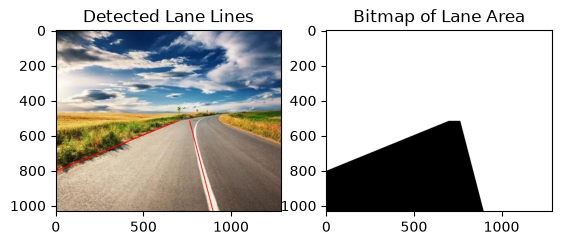

In [222]:
y_top, y_bot = int(h * 0.50), h - 1

points = np.array([
    [int(x_cord(left, y_top)), y_top],
    [int(x_cord(left, y_bot)), y_bot],
    [int(x_cord(right, y_bot)), y_bot],
    [int(x_cord(right, y_top)), y_top]
], dtype=np.int32)

bitmap = np.full((h, w), 255, dtype=np.uint8)
cv2.fillPoly(bitmap, [points], 0)

plt.imsave("output.png", bitmap)

img1 = img.copy()
cv2.line(img1, (int(x_cord(left, y_top)), y_top), (int(x_cord(left, y_bot)), y_bot), (0, 0, 255), 3)
cv2.line(img1, (int(x_cord(right, y_top)), y_top), (int(x_cord(right, y_bot)), y_bot), (0, 0, 255), 3)
plt.subplot(1, 2, 1); plt.imshow(cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)); plt.title("Detected Lane Lines")
plt.subplot(1, 2, 2); plt.imshow(bitmap, cmap="gray"); plt.title("Bitmap of Lane Area")
plt.show()